# 02_EDA — Analyse exploratoire ciblée (train seul)

**Projet :** Credit Risk Scorecard · **Phase 3** — sous-ensemble 3b · Données : Home Credit Default Risk (Kaggle).

- Échantillons chargés exclusivement par `load_split` (`scripts/make_splits.py`) : **train seul** ; la validation n'est pas utilisée ici et le test est scellé (D15).
- Objectif : décrire la relation entre les variables candidates et `TARGET` (taux de défaut par segment, forme des relations, manquants informatifs) pour préparer le binning (D17, notebook `03_WoE_Binning`) et la sélection (D18, D19).
- Le notebook ouvre la base **en lecture seule** ; il n'écrit que les figures `output/02_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from build_feature_catalog import CAND, CATALOG
from config import DB_PATH, FIGURES_DIR
from make_splits import load_split

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 et 01
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


## 1. Échantillon d'apprentissage

Chargement du **train seul** (70 %) et contrôle de son empreinte par rapport à celle enregistrée au découpage (`split_meta`, D15).

In [ ]:
train = load_split(con, "train")
y = train["TARGET"]
rate_global = 100 * y.mean()

# Empreinte des identifiants chargés = empreinte enregistrée au découpage ?
fp_loaded = hashlib.sha256("\n".join(str(int(i)) for i in sorted(train["SK_ID_CURR"])).encode("ascii")).hexdigest()
fp_saved = con.execute("SELECT ids_sha256 FROM split_meta WHERE split = 'train'").fetchone()[0]
if fp_loaded != fp_saved:
    raise RuntimeError("Le train chargé ne correspond pas au découpage enregistré (split_meta).")

candidates = [c for c in train.columns if CATALOG[c][3] == CAND]
print(f"Train : {len(train):,} lignes × {train.shape[1]} colonnes ; taux de défaut {rate_global:.2f} %")
print(f"Empreinte conforme à split_meta : {fp_loaded[:16]}…")
print(f"Variables candidates (statut « {CAND} », D16) : {len(candidates)}")

Train : 215,257 lignes × 208 colonnes ; taux de défaut 8.07 %
Empreinte conforme à split_meta : 040198046e562a17…
Variables candidates (statut « candidate », D16) : 200


## 2. Taux de défaut par segment (variables catégorielles)

Pour chaque modalité : effectif, part du train, taux de défaut et écart au taux global (en points).
Les modalités de moins de 1 % du train sont conservées dans le tableau, mais leur taux est fragile : le binning (D17) imposera au moins 5 % d'individus par classe.

In [3]:
def default_by(s: pd.Series, target: pd.Series) -> pd.DataFrame:
    """Effectif, part et taux de défaut par modalité ; valeur manquante = « (manquant) »."""
    key = s.astype("string").fillna("(manquant)")
    t = (
        pd.DataFrame({"modalite": key.to_numpy(), "TARGET": target.to_numpy()})
        .groupby("modalite", observed=True)["TARGET"]
        .agg(n="size", taux="mean")
        .reset_index()
    )
    t["part_pct"] = 100 * t["n"] / t["n"].sum()
    t["taux_defaut_pct"] = 100 * t["taux"]
    t["ecart_pt"] = t["taux_defaut_pct"] - 100 * target.mean()
    return t.drop(columns="taux").sort_values("taux_defaut_pct", ascending=False, ignore_index=True)


SEGMENTS = [
    "NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE", "REGION_RATING_CLIENT", "OCCUPATION_TYPE",
]
seg_tables = {}
fmt = {"part_pct": "{:.2f}", "taux_defaut_pct": "{:.2f}", "ecart_pt": "{:+.2f}", "n": "{:,}"}
for col in SEGMENTS:
    seg_tables[col] = default_by(train[col], y)
    display(Markdown(f"**{col}**"))
    display(seg_tables[col].style.format(fmt).hide(axis="index"))

**NAME_CONTRACT_TYPE**

modalite,n,part_pct,taux_defaut_pct,ecart_pt
Cash loans,"194,675",90.44,8.34,+0.27
Revolving loans,"20,582",9.56,5.55,-2.52


**NAME_INCOME_TYPE**

modalite,n,part_pct,taux_defaut_pct,ecart_pt
Unemployed,16,0.01,31.25,+23.18
Working,"110,984",51.56,9.53,+1.46
Commercial associate,"50,106",23.28,7.58,-0.49
State servant,"15,382",7.15,5.89,-2.18
Pensioner,"38,748",18.00,5.39,-2.68
Businessman,9,0.00,0.00,-8.07
Maternity leave,3,0.00,0.00,-8.07
Student,9,0.00,0.00,-8.07


**NAME_EDUCATION_TYPE**

...

modalite,n,part_pct,taux_defaut_pct,ecart_pt
Rented apartment,"3,357",1.56,12.45,+4.38
With parents,"10,330",4.80,11.62,+3.54
Co-op apartment,791,0.37,9.36,+1.28
Municipal apartment,"7,803",3.62,8.33,+0.26
House / apartment,"191,159",88.81,7.80,-0.27
Office apartment,"1,817",0.84,6.77,-1.30


**REGION_RATING_CLIENT**

modalite,n,part_pct,taux_defaut_pct,ecart_pt
3,"33,860",15.73,11.01,+2.93
2,"158,846",73.79,7.92,-0.15
1,"22,551",10.48,4.74,-3.33


**OCCUPATION_TYPE**

modalite,n,part_pct,taux_defaut_pct,ecart_pt
Low-skill Laborers,"1,480",0.69,17.91,+9.83
Waiters/barmen staff,924,0.43,11.69,+3.62
Drivers,"13,088",6.08,11.12,+3.05
Security staff,"4,698",2.18,10.75,+2.68
Laborers,"38,591",17.93,10.58,+2.50
Cooking staff,"4,178",1.94,10.53,+2.46
Cleaning staff,"3,310",1.54,9.61,+1.53
Sales staff,"22,285",10.35,9.55,+1.48
Realty agents,524,0.24,7.82,-0.25
Medicine staff,"6,050",2.81,7.07,-1.00


## 3. Forme de la relation (variables numériques, par décile)

Taux de défaut par décile de la variable (classe « manquant » en gris, à droite). Une relation **monotone** se prête directement au binning optimal monotone (D17) ; une relation en U serait à signaler.

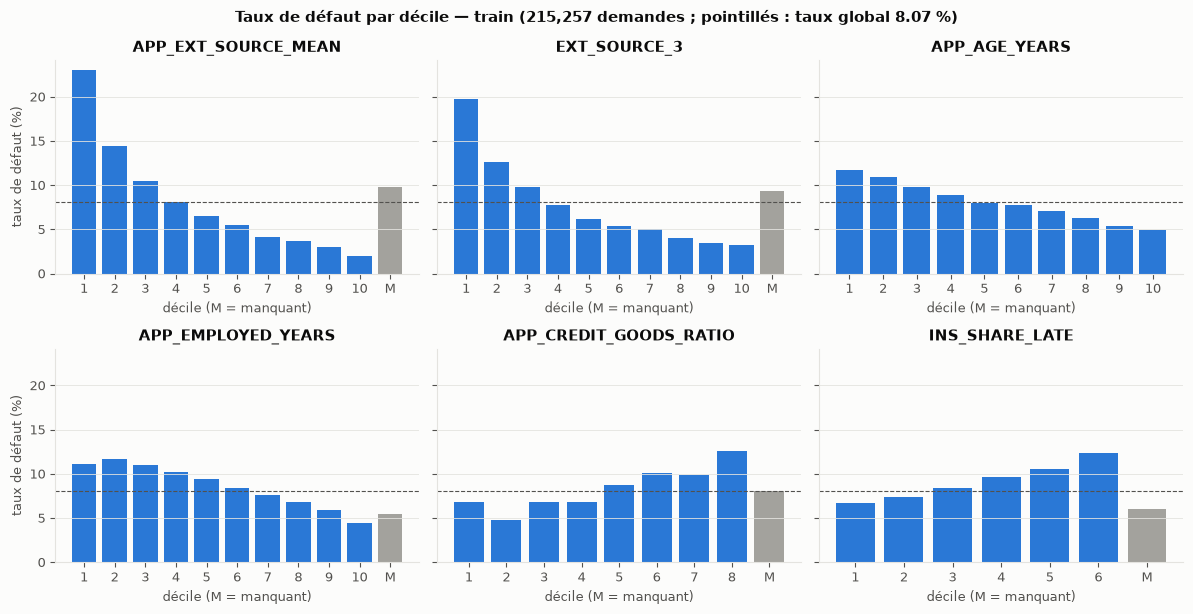

In [4]:
def default_by_quantile(s: pd.Series, target: pd.Series, q: int = 10) -> pd.DataFrame:
    """Taux de défaut par quantile de s (classes égales en effectif) ; les manquants forment une classe à part."""
    bins = pd.qcut(s, q=q, duplicates="drop")
    d = pd.DataFrame({"classe": bins, "TARGET": target.to_numpy()})
    t = d.groupby("classe", observed=True, dropna=False)["TARGET"].agg(n="size", taux="mean").reset_index()
    t["manquant"] = t["classe"].isna()
    t["classe"] = t["classe"].astype("string").fillna("(manquant)")
    t["taux_defaut_pct"] = 100 * t["taux"]
    return t.drop(columns="taux")


NUMERIC_VIEW = [
    "APP_EXT_SOURCE_MEAN", "EXT_SOURCE_3", "APP_AGE_YEARS",
    "APP_EMPLOYED_YEARS", "APP_CREDIT_GOODS_RATIO", "INS_SHARE_LATE",
]
quant_tables = {c: default_by_quantile(train[c], y) for c in NUMERIC_VIEW}

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharey=True)
for ax, col in zip(axes.flat, NUMERIC_VIEW):
    t = quant_tables[col]
    colors = [GREY if m else BLUE for m in t["manquant"]]
    ax.bar(range(len(t)), t["taux_defaut_pct"], color=colors)
    ax.axhline(rate_global, color=INK2, lw=0.8, ls="--")
    ax.set_title(col)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(["M" if m else str(i + 1) for i, m in enumerate(t["manquant"])])
    ax.set_xlabel("décile (M = manquant)")
    ax.grid(axis="y", color=GRID, lw=0.6)
for ax in axes[:, 0]:
    ax.set_ylabel("taux de défaut (%)")
fig.suptitle(f"Taux de défaut par décile — train ({len(train):,} demandes ; pointillés : taux global {rate_global:.2f} %)",
             fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_default_rate_by_decile.png", dpi=150)
plt.show()

## 4. Manquants informatifs

Pour chaque variable candidate numérique ayant entre 1 % et 99 % de valeurs manquantes : taux de défaut quand la valeur est **manquante** comparé à quand elle est **renseignée**.
Un écart important confirme qu'il faut garder les manquants dans une **classe à part** plutôt que les imputer (D7, D17).

Variables candidates numériques : 186 ; avec 1 à 99 % de manquants : 106
Écart absolu ≥ 1 point : 83 variables


variable,pct_manquants,taux_si_manquant_pct,taux_si_renseigne_pct,ecart_pt
APP_EMPLOYED_YEARS,18.00,5.41,8.66,-3.25
APP_EMPLOYED_AGE_RATIO,18.00,5.41,8.66,-3.25
AMT_REQ_CREDIT_BUREAU_YEAR,13.51,10.48,7.70,+2.78
AMT_REQ_CREDIT_BUREAU_HOUR,13.51,10.48,7.70,+2.78
AMT_REQ_CREDIT_BUREAU_QRT,13.51,10.48,7.70,+2.78
AMT_REQ_CREDIT_BUREAU_MON,13.51,10.48,7.70,+2.78
AMT_REQ_CREDIT_BUREAU_WEEK,13.51,10.48,7.70,+2.78
AMT_REQ_CREDIT_BUREAU_DAY,13.51,10.48,7.70,+2.78
BUR_YEARS_SINCE_LAST_CREDIT,14.33,10.27,7.71,+2.56
BUR_SUM_CREDIT,14.33,10.27,7.71,+2.56


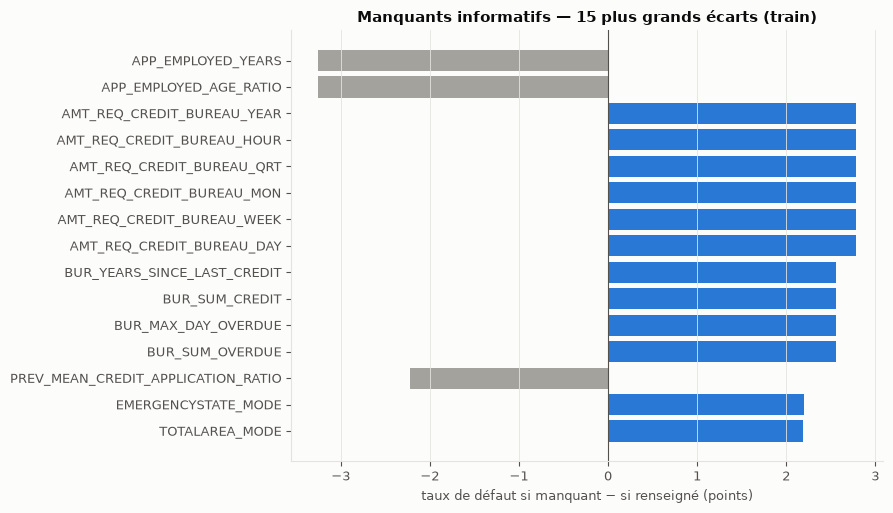

In [ ]:
num_cand = [c for c in candidates if pd.api.types.is_numeric_dtype(train[c])]
rows = []
for c in num_cand:
    m = train[c].isna()
    share = m.mean()
    if 0.01 <= share <= 0.99:
        rows.append({
            "variable": c,
            "pct_manquants": 100 * share,
            "taux_si_manquant_pct": 100 * y[m].mean(),
            "taux_si_renseigne_pct": 100 * y[~m].mean(),
        })
miss = pd.DataFrame(rows)
miss["ecart_pt"] = miss["taux_si_manquant_pct"] - miss["taux_si_renseigne_pct"]
miss = miss.sort_values("ecart_pt", key=np.abs, ascending=False, ignore_index=True)

print(f"Variables candidates numériques : {len(num_cand)} ; avec 1 à 99 % de manquants : {len(miss)}")
print(f"Écart absolu ≥ 1 point : {int((miss['ecart_pt'].abs() >= 1).sum())} variables")
display(miss.head(20).style.format({"pct_manquants": "{:.2f}", "taux_si_manquant_pct": "{:.2f}",
                                    "taux_si_renseigne_pct": "{:.2f}", "ecart_pt": "{:+.2f}"}).hide(axis="index"))

top = miss.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top["variable"], top["ecart_pt"], color=[BLUE if v > 0 else GREY for v in top["ecart_pt"]])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("taux de défaut si manquant − si renseigné (points)")
ax.set_title("Manquants informatifs — 15 plus grands écarts (train)")
ax.grid(axis="x", color=GRID, lw=0.6)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_missing_informative.png", dpi=150)
plt.show()

## 5. Contrôle D1 : drapeau `DAYS_EMPLOYED` et retraités

Le drapeau `APP_FLAG_DAYS_EMPLOYED_ANOM` recoupe presque entièrement `NAME_INCOME_TYPE = 'Pensioner'`. Les deux variables portent la même information : leur colinéarité sera traitée par la corrélation des WoE et le VIF (D19).

In [ ]:
pens = train["NAME_INCOME_TYPE"].astype("string").eq("Pensioner").fillna(False)
flag = train["APP_FLAG_DAYS_EMPLOYED_ANOM"].eq(1)
cross = (
    pd.DataFrame({"drapeau_anom": flag.to_numpy(), "retraite": pens.to_numpy(), "TARGET": y.to_numpy()})
    .groupby(["drapeau_anom", "retraite"])["TARGET"].agg(n="size", taux="mean").reset_index()
)
cross["taux_defaut_pct"] = 100 * cross["taux"]
display(cross.drop(columns="taux").style.format({"n": "{:,}", "taux_defaut_pct": "{:.2f}"}).hide(axis="index"))
overlap = (flag & pens).sum() / flag.sum()
print(f"Part des demandes avec drapeau qui sont des retraités : {100 * overlap:.2f} %")

drapeau_anom,retraite,n,taux_defaut_pct
False,False,"176,493",8.66
False,True,8,0.00
True,False,16,31.25
True,True,"38,740",5.39


Part des demandes avec drapeau qui sont des retraités : 99.96 %


## 6. Synthèse

In [7]:
def worst_segment(t: pd.DataFrame) -> str:
    big = t[t["part_pct"] >= 1]
    r = big.iloc[0]
    return f"{r['modalite']} ({r['taux_defaut_pct']:.2f} %, {r['part_pct']:.1f} % du train)"

ext = quant_tables["APP_EXT_SOURCE_MEAN"]
ext_rates = ext.loc[~ext["manquant"], "taux_defaut_pct"]
top3 = miss.head(3)

display(Markdown(f"""
**Constats (train, {len(train):,} demandes, taux de défaut {rate_global:.2f} %)**
- Segments les plus risqués (modalités ≥ 1 % du train) : type de revenu {worst_segment(seg_tables["NAME_INCOME_TYPE"])} ;
  éducation {worst_segment(seg_tables["NAME_EDUCATION_TYPE"])} ; profession {worst_segment(seg_tables["OCCUPATION_TYPE"])}.
- `APP_EXT_SOURCE_MEAN` : taux de défaut de {ext_rates.iloc[0]:.2f} % dans le 1er décile à {ext_rates.iloc[-1]:.2f} % dans le dernier,
  soit un rapport de {ext_rates.iloc[0] / ext_rates.iloc[-1]:.1f} : variable très discriminante, probablement à IV élevé (revue prévue par D18).
- Manquants informatifs : {int((miss['ecart_pt'].abs() >= 1).sum())} variables candidates avec un écart d'au moins 1 point ;
  les plus marqués : {", ".join(f"`{r.variable}` ({r.ecart_pt:+.2f} pt)" for r in top3.itertuples())}.
- D1 : {100 * overlap:.2f} % des demandes avec drapeau `DAYS_EMPLOYED` sont des retraités → colinéarité à traiter en sélection (D19).

**Implications pour le binning (notebook `03_WoE_Binning`)**
1. Manquants dans une classe à part (D7, D17), confirmé par les écarts de taux observés.
2. Relations majoritairement monotones sur les variables examinées : tendance monotone automatique (D17).
3. Modalités rares des variables catégorielles : regroupées par le binning (au moins 5 % par classe).
"""))


**Constats (train, 215,257 demandes, taux de défaut 8.07 %)**
- Segments les plus risqués (modalités ≥ 1 % du train) : type de revenu Working (9.53 %, 51.6 % du train) ;
  éducation Lower secondary (11.00 %, 1.2 % du train) ; profession Drivers (11.12 %, 6.1 % du train).
- `APP_EXT_SOURCE_MEAN` : taux de défaut de 22.99 % dans le 1er décile à 1.98 % dans le dernier,
  soit un rapport de 11.6 : variable très discriminante, probablement à IV élevé (revue prévue par D18).
- Manquants informatifs : 83 variables candidates avec un écart d'au moins 1 point ;
  les plus marqués : `APP_EMPLOYED_YEARS` (-3.25 pt), `APP_EMPLOYED_AGE_RATIO` (-3.25 pt), `AMT_REQ_CREDIT_BUREAU_YEAR` (+2.78 pt).
- D1 : 99.96 % des demandes avec drapeau `DAYS_EMPLOYED` sont des retraités → colinéarité à traiter en sélection (D19).

**Implications pour le binning (notebook `03_WoE_Binning`)**
1. Manquants dans une classe à part (D7, D17), confirmé par les écarts de taux observés.
2. Relations majoritairement monotones sur les variables examinées : tendance monotone automatique (D17).
3. Modalités rares des variables catégorielles : regroupées par le binning (au moins 5 % par classe).


In [8]:
con.close()